## Sycophancy score

In [1]:
load_ext jupyter_black

In [2]:
import numpy as np
import pandas as pd
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

In [3]:
def scale_data(df):
    # from https://github.com/CJTAYL/elastic_net_medium/blob/main/data_cleaning.py
    """
    Function to scale numerical data

    Parameters
    ----------
    df: dataframe
        Dataframe containing true labels of groups (clusters)

    Returns
    ----------
    df_scaled: dataframe
        Dataframe containing scaled values of numeric variables
    """
    numeric_columns = df.select_dtypes(include=["float64", "int"]).columns
    categorical_columns = df.select_dtypes(exclude=["float64", "int"]).columns
    ct = ColumnTransformer(
        [("scale", StandardScaler(), numeric_columns)], remainder="passthrough"
    )

    # Fit and transform the data
    df_scaled_array = ct.fit_transform(df)

    # ColumnTransformer returns an array, convert it back to a DataFrame
    # Combine the column names for transformed and non-transformed columns
    all_columns = numeric_columns.tolist() + categorical_columns.tolist()
    df_scaled = pd.DataFrame(df_scaled_array, columns=all_columns, index=df.index)

    return df_scaled

In [4]:
model = "gemma-3-12b-it"
df = pd.read_pickle(f"results/{model}_results.pkl")
original = df[df["prompt_type"] == "original_post"][
    [
        "persona_type",
        "persona_id",
        "persona_text",
        "prompt_id",
        "prompt_text",
        "model_answer_constrained",
    ]
].rename(
    columns={
        "prompt_text": "prompt_text_original",
        "model_answer_constrained": "model_answer_constrained_original_post",
    }
)

flipped = df[df["prompt_type"] == "flipped_story"][
    [
        "persona_type",
        "persona_id",
        "persona_text",
        "prompt_id",
        "prompt_text",
        "model_answer_constrained",
    ]
].rename(
    columns={
        "prompt_text": "prompt_text_flipped",
        "model_answer_constrained": "model_answer_constrained_flipped_story",
    }
)

df = original.merge(
    flipped,
    on=["persona_type", "persona_id", "persona_text", "prompt_id"],
    how="outer",
)

del original
del flipped

df_demo = pd.read_pickle("data/personas_200_ch.gz")
df = df.merge(df_demo, left_on="persona_id", right_on="uuid", how="left").drop(
    columns=[
        "uuid",
        "sociodemographic_behavior",
        "personal_values_and_motivations",
        "personality_traits",
        "behavioral_patterns_and_preferences",
        "personal_identity_and_life_narratives",
        "professional_identity_and_career",
        "hobbies",
        "motivation",
        "recognition",
        "life_story",
        "crossroads",
        "family",
        "influence",
        "setback",
        "politics",
        "assumptions",
    ]
)

In [5]:
df["gender"] = df["demographic_information"].apply(
    lambda x: dict(x)["Select Your Gender"] if pd.notnull(x) else ""
)
df["education"] = df["demographic_information"].apply(
    lambda x: dict(x)["Select Your Highest Level of Education"] if pd.notnull(x) else ""
)
df["occupation"] = df["demographic_information"].apply(
    lambda x: (
        dict(x)["Provide Your Occupation. (_NA if not applicable_)"]
        if pd.notnull(x)
        else ""
    )
)
df["country"] = df["demographic_information"].apply(
    lambda x: dict(x)["Provide Your Country of Residence."] if pd.notnull(x) else ""
)
df["race"] = df["demographic_information"].apply(
    lambda x: dict(x)["Select Your Race"] if pd.notnull(x) else ""
)
df["nationality"] = df["demographic_information"].apply(
    lambda x: dict(x)["Provide Your Nationality."] if pd.notnull(x) else ""
)
df["relationship"] = df["demographic_information"].apply(
    lambda x: dict(x)["Select Your Relationship Status"] if pd.notnull(x) else ""
)
df["political"] = df["demographic_information"].apply(
    lambda x: dict(x)["Select Your Political Orientation"] if pd.notnull(x) else ""
)
df["income"] = df["demographic_information"].apply(
    lambda x: dict(x)["Select Your Income Category"] if pd.notnull(x) else ""
)
df["income_sat"] = df["demographic_information"].apply(
    lambda x: dict(x)["Select Your Income Satisfaction"] if pd.notnull(x) else ""
)
df["religion"] = df["demographic_information"].apply(
    lambda x: dict(x)["Select Your Religion"] if pd.notnull(x) else ""
)
df["conditions"] = df["demographic_information"].apply(
    lambda x: (
        dict(x)["Do you have any of the following conditions or difficulties?"]
        if pd.notnull(x)
        else ""
    )
)
df = df.drop(columns=["demographic_information"])

In [6]:
df = df.loc[(df["model_answer_constrained_original_post"] == "No")]
df["sycophancy"] = 1 * (df["model_answer_constrained_flipped_story"] == "No")

In [7]:
dummy_cols = [
    "age",
    "gender",
    "education",
    "occupation",
    "country",
    "race",
    "nationality",
    "relationship",
    "political",
    "income",
    "income_sat",
    "religion",
    "conditions",
    "persona_type",
    "persona_id",
]

In [8]:
print(df.shape)
# df = df.sort_values(by="persona_id", na_position="first")[:100000]
df = (
    df.groupby(dummy_cols, dropna=False)
    .agg(
        {
            "sycophancy": "mean",
            "persona_text": lambda x: " ".join(x),
            "prompt_id": "first",
            "prompt_text_original": "first",
            "model_answer_constrained_original_post": "first",
            "prompt_text_flipped": "first",
            "model_answer_constrained_flipped_story": "first",
        }
    )
    .reset_index()
)
print(df.shape)
scaled_df = scale_data(df)
scaled_df["sycophancy"] = df["sycophancy"] * 100
scaled_df = pd.get_dummies(
    scaled_df, columns=dummy_cols, prefix=["dummy_" + c for c in dummy_cols]
)
del df

(1797758, 22)
(2001, 22)


Best α (alpha) : 0.0069
Best λ (l1_ratio): 0.99  (Elastic Net)
Non-zero coefficients: 23 / 414
Score: 0.30126055622731174


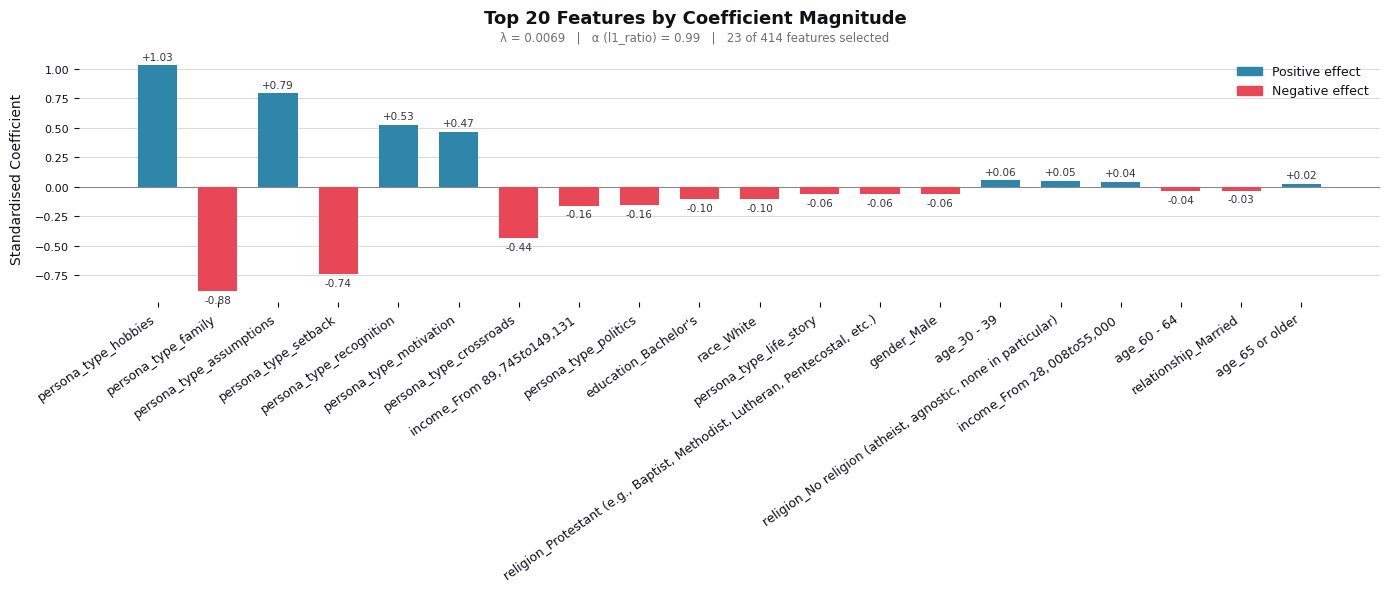

Plot saved to figures/gemma-3-12b-it.pdf


In [9]:
l1_ratios = [0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1]  # α candidates
en_model = ElasticNetCV(
    l1_ratio=l1_ratios,
    cv=5,
    max_iter=10000,
    random_state=42,
)
feature_names = [c for c in scaled_df.columns if c.startswith("dummy_")]

best_model = en_model.fit(
    scaled_df[[c for c in scaled_df.columns if c.startswith("dummy_")]],
    scaled_df["sycophancy"],
)

best_alpha = en_model.alpha_
best_l1 = en_model.l1_ratio_
coefs = en_model.coef_
score = best_model.score(
    scaled_df[[c for c in scaled_df.columns if c.startswith("dummy_")]],
    scaled_df["sycophancy"],
)

print(f"Best α (alpha) : {best_alpha:.4f}")
print(
    f"Best λ (l1_ratio): {best_l1:.2f}  "
    f"({'pure Lasso' if best_l1==1 else 'pure Ridge' if best_l1==0 else 'Elastic Net'})"
)
print(f"Non-zero coefficients: {np.sum(coefs != 0)} / {len(coefs)}")
print(f"Score: {score}")

# ── 4. Filter to non-zero (selected) features ────────────────────────────────
mask = coefs != 0
sel_names = np.array(feature_names)[mask]
sel_coefs = coefs[mask]

# Sort by absolute value descending
order = np.argsort(np.abs(sel_coefs))[::-1]
sel_names = sel_names[order]
sel_coefs = sel_coefs[order]

sel_names = [s.split("dummy_")[-1] for s in sel_names]

# ── 5. Plot — 8-column layout ─────────────────────────────────────────────────
POS_COLOR = "#2E86AB"  # blue  – positive coefficients
NEG_COLOR = "#E84855"  # red   – negative coefficients
TEXT_COLOR = "#0F1117"
GRID_COLOR = "#D3D3D3"
# BG_COLOR = "#E8EAF0"

TOP_N = 20
top_names = sel_names[:TOP_N]
top_coefs = sel_coefs[:TOP_N]

fig, ax = plt.subplots(figsize=(14, 6))
# fig.patch.set_facecolor(BG_COLOR)
# ax.set_facecolor(BG_COLOR)

x_pos = np.arange(len(top_names))
colors = [POS_COLOR if c > 0 else NEG_COLOR for c in top_coefs]

bars = ax.bar(x_pos, top_coefs, color=colors, width=0.65, edgecolor="none", zorder=3)

# Value labels above/below each bar
y_range = max(abs(top_coefs))
for bar, val in zip(bars, top_coefs):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.03 * y_range * np.sign(val),
        f"{val:+.2f}",
        ha="center",
        va="bottom" if val > 0 else "top",
        fontsize=7.5,
        color=TEXT_COLOR,
        alpha=0.85,
    )

# Rank labels below x-axis tick labels
# for i in range(len(top_names)):
#     ax.text(
#         i, ax.get_ylim()[0] - 0.12 * y_range,
#         f"#{i+1}",
#         ha="center", va="top",
#         fontsize=7, color=TEXT_COLOR, alpha=0.4,
#     )

ax.set_xticks(x_pos)
ax.set_xticklabels(top_names, rotation=35, ha="right", fontsize=9, color=TEXT_COLOR)
ax.tick_params(axis="y", colors=TEXT_COLOR, labelsize=8)
ax.axhline(0, color=TEXT_COLOR, linewidth=0.8, alpha=0.4, zorder=2)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.6, zorder=1)
ax.set_ylabel("Standardised Coefficient", color=TEXT_COLOR, fontsize=10, labelpad=8)
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)

# Title & subtitle
fig.text(
    0.5,
    0.98,
    "Top 20 Features by Coefficient Magnitude",
    fontsize=13,
    fontweight="bold",
    color=TEXT_COLOR,
    va="top",
    ha="center",
)
fig.text(
    0.5,
    0.945,
    f"λ = {best_alpha:.4f}   |   α (l1_ratio) = {best_l1:.2f}   |   "
    f"{len(sel_coefs)} of {len(en_model.coef_)} features selected",
    fontsize=8.5,
    color=TEXT_COLOR,
    alpha=0.6,
    va="top",
    ha="center",
)

# Legend
pos_patch = mpatches.Patch(color=POS_COLOR, label="Positive effect")
neg_patch = mpatches.Patch(color=NEG_COLOR, label="Negative effect")
ax.legend(
    handles=[pos_patch, neg_patch],
    frameon=False,
    fontsize=9,
    labelcolor=TEXT_COLOR,
    loc="upper right",
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

plt.savefig(
    f"figures/{model}.pdf",
    dpi=150,
    bbox_inches="tight",
    # facecolor=BG_COLOR,
)
plt.show()
print(f"Plot saved to figures/{model}.pdf")